In [8]:
using Plots,Distributions, JLD, DSP, Parameters, Match, SymDict, NumericalIntegration, Random, MAT, Pkg, CSV, DataFrames, XLSX, Pkg, JLD2, Colors, ColorSchemes, JLD2,  Makie, CairoMakie, Optim, Serialization, JuMP, Ipopt, Wandb, PyCall,Logging, GLM, PyPlot, Polynomials

include("creation_model.jl")
include("calculate_rates_with_timebase.jl")
include("filter_input.jl") 
# include("run_sim.jl")
include("run_simulation.jl")
include("conv_spikes.jl") 
# include("firing_rates_max.jl") 


conv_spikes (generic function with 1 method)

In [2]:
function run_sim_optim_constant_inh()

    for i in 1:nr_s
        # temp = filter_input(50,rand(Normal(0, 1),sim_length+2000))  # add some gaussian noise - optional
        # independantnoise[i,:] = temp[1001:end-1000] * 0.25;

        full_input[i,:] = commoninput # + independantnoise[i,:]; 
        vd, vs, _,pt, mt, ht, nt, qt = ode4(tspan, 0.,0., i, pool_state_params[i], full_input[i,:], inh_input, MNs)      
        spikes = spikes_from_aps(vs, i, MNs)       
        spike_arr[i,:] = spikes
        vs_arr[i,:] = vs
        pt_arr[i,:] = pt;mt_arr[i,:] = mt;ht_arr[i,:] = ht;nt_arr[i,:] = nt;qt_arr[i,:] = qt
    end
    return spike_arr, vs_arr,pt_arr
end

run_sim_optim_constant_inh (generic function with 1 method)

## MN parameters 

#### Slow-type motoneurons

In [82]:
######################  S-TYPE ##########################
#########################################################
nr_s = 87

# JLD2.@load "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/VthCaTA_gamma07_29Jul.jld2" VthCa_newTA
# JLD2.@load "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/VthCa_TA_5sept.jld2" VthCa_newTA
# JLD2.@load "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/VthCaVL_gamma07_28Jul.jld2" VthCa_newVL
# JLD2.@load "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/VthCa_VL_6sept.jld2" VthCa_newVL
JLD2.@load "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/VthCa_TA_6sept.jld2" VthCa_newTA

# Radius and soma lengths
rheobase_S = LinRange(3.5,6.5,nr_s) .+ rand(Normal(0.0,0.05),nr_s)  
rs_S = LinRange(38.75,41.25,nr_s)./10000 
ls_S = LinRange(77.5,82.5,nr_s)./10000 
rms_S = LinRange(1.15, 1.05,nr_s).*1000
rd_S = LinRange(20.75,31.25,nr_s)./10000 
ld_S = LinRange(5500.,6800.,nr_s)./10000 
rmd_S = LinRange(14.4,10.70,nr_s).*1000 

#  Maximun conductances for each of the ION channels mS/cm^2 
max_gna = 30.0 
max_gkf_S = ones(nr_s)*4 
max_gks_S =LinRange(16,25,nr_s) 
max_gca_S = LinRange(0.038,0.029,nr_s) 


# Rate constants of the kinetic processes in ms^-1
αm = ones(nr_s)*22.0
βm = ones(nr_s)*13.0

αh_S = ones(nr_s)*0.5
βh_S = ones(nr_s)*4

αn_S = ones(nr_s)*1.5
βn_S = ones(nr_s)*0.1

αq_S = ones(nr_s)*1.5
βq_S = LinRange(0.025,0.038,nr_s) 

αp_D = 0.008
βp_D = LinRange(0.014,0.016,nr_s) 

Vthca_S = VthCa_newTA[1,:] # vcat(LinRange(2.5,3.,nr_s)) # VthCa_newTA[1,:]
Apeak_S = LinRange(0.103,0.123,nr_s)
tpeak_S = LinRange(110.,100.,nr_s) 
tetanic_S = LinRange(0.393,0.491,nr_s);


#EXCITATORY PROFILE
amplitude=0.4
tr_length=28000
half_triang = div(tr_length, 2)  
flat_line = fill(-0.1, 1000)
up = range(-0.1, amplitude, length = half_triang + 1)  
down = range(amplitude, -0.1, length = tr_length - half_triang + 1)  
tr = vcat(flat_line, up[2:end], down[2:end], flat_line)
sim_length=30000

# at some point delete these things
γa=1.;
γh = ones(nr_s)*0.7
IF= LinRange(1.,1.,nr_s);  #factor for the inhibtion

#reversal potentials
EL=0; ENa=120; ECa=140; EK=-10; Ee=70; Ei=-16 

#maximun conductances
Ge=0.6; Gi=0.5 ; 

#initial voltages
Vd0 = 0.; 
Vs0 = 0.;

#refractory period
rp=5.0; 

const step = 0.05;
_int(num) = floor(Int, num);

#Pulse duration [mS]
pd=1; 


In [3]:
# flat_length = 20000

# # Calculate the remaining length for rising and falling edges
# remaining_length = sim_length - flat_length
# edge_length = div(remaining_length, 2)

# # Create the flat sections
# flat = fill(amplitude, flat_length)

# # Create the rising and falling edges
# up = range(0, stop = amplitude, length = edge_length + 1)
# down = range(amplitude, stop = 0, length = edge_length + 1)

# # Concatenate the sections to form the trapezoid
# tr = vcat(up[2:end], flat, down[2:end])

# Plots.plot(tr)

In [4]:
# ## sinusoid frequency 3 Hz
# # frequency = 3 

# # x_values = range(0, stop=frequency*2π, length=sim_length)
# # tr = (amplitude / 2) * sin.(x_values .- π/2) .+ (amplitude / 2)
# sim_length=5000
# frequency = 0.25     # Frequency in Hz
# amplitude_min = 0.16
# amplitude_max = 0.3
# duration = 5      # Duration in seconds

# # Time array
# t = range(0, stop=duration, length=sim_length)

# # Generate the sinusoidal signal with a frequency of 3 Hz
# x_values = 2 * π * frequency * t
# signal = sin.(x_values .- π/2)  # Adjust phase to start at minimum

# # Scale the signal to range from 0.16 to 0.4
# signal = (signal .+ 1) / 2  # Normalize to range [0, 1]
# tr = signal * (amplitude_max - amplitude_min) .+ amplitude_min  # Scale to range [0.16, 0.4]


# # Plot the trajectory
# Plots.plot(x_values, tr, label="Trajectory", legend=false, linewidth=6, color=:blue, grid=false)


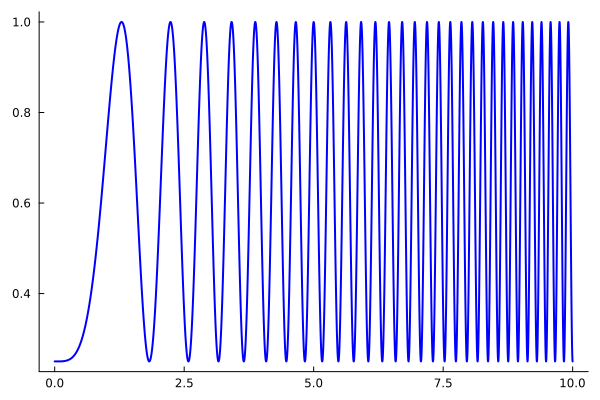

In [5]:
# ## chirp
# # sim_length=10000

# duration = 10.0  # Duration in seconds
# points = 10000   # Number of points in the x-axis
# f0 = 0           # Starting frequency
# f1 = 3.0         # Ending frequency
# amplitude_min = 0.25
# amplitude_max = 1

# # Time array
# t = range(0, stop=duration, length=points)

# # Generate chirp signal with phase adjustment
# phase = 2 * π * (f0 .+ (f1 - f0) .* t / duration) .* t
# signal = sin.(phase .- π/2)  # Adjust phase to start at minimum

# # Scale the signal to range from 0.16 to 0.4
# signal = (signal .+ 1) / 2  # Normalize to range [0, 1]
# tr = signal * (amplitude_max - amplitude_min) .+ amplitude_min  # Scale to range [0.16, 0.4]

# # Ensure the signal starts and ends at amplitude_min
# tr[1] = amplitude_min
# tr[end] = amplitude_min

# Plots.plot(t, tr, label="Chirp Signal", legend=false, linewidth=2, color=:blue, grid=false)


In [47]:

# flat_length = 20000
# remaining_length = sim_length - flat_length
# edge_length = div(remaining_length, 2)
# flat = fill(amplitude, flat_length)
# up = range(0, stop = amplitude, length = edge_length + 1)
# down = range(amplitude, stop = 0, length = edge_length + 1)
# tr = vcat(up[2:end], flat, down[2:end])


# Plots.plot([1:30000],tr,linewidth=6, color=:blue, grid=false, legend=false)


### MN parameters we need to fill with previous data (and creation of the dictionary)

In [83]:
ri = 70.  # Ω.cm 3intracellular resistivity
cm = 1.; #membrane capacitance

MN_list=[];
Vth_S = zeros(nr_s); gls_S = zeros(nr_s); gld_S = zeros(nr_s); gc_S = zeros(nr_s); gna_S = zeros(nr_s); gkf_S = zeros(nr_s); gks_S = zeros(nr_s); gca_S = zeros(nr_s); rn_S = zeros(nr_s); cs_S = zeros(nr_s)  ; cd_S = zeros(nr_s)
for i in 1:nr_s 
    ##assuming that the somatic membrane can be modeled as a cylinder and using the defined parameters from the previous section
    gls_S[i] = ((2*π*rs_S[i]*ls_S[i])/rms_S[i])*1e6  # conductance of the soma for the ith neuron (uS)
    gld_S[i] = ((2*π*rd_S[i]*ld_S[i])/rmd_S[i])*1e6  # # conductance of the dendrite for the ith neuron (uS)
    gc_S[i] = ((2/(((ri*ld_S[i])/(π*rd_S[i]^2))+((ri*ls_S[i])/(π*rs_S[i]^2)))))*1e6    # coupling conductance in uS
    rn_S[i] = 1/(gls_S[i]+((gld_S[i]*gc_S[i])/(gld_S[i]+gc_S[i]))) # input resistance of the neuron in MΩ     
    Vth_S[i] = round(rn_S[i]*rheobase_S[i],digits=2)   # in mV ohms law
    cs_S[i] = 2*π*ls_S[i]*rs_S[i]*cm*1e3   #inner capacitance of the soma nF
    cd_S[i] = 2*π*ld_S[i]*rd_S[i]*cm*1e3   #nF
    
    #conductances uS:
    gna_S[i] = 2*π*ls_S[i]*rs_S[i]*max_gna*1e3          
    gkf_S[i] = 2*π*ls_S[i]*rs_S[i]*max_gkf_S[i]*1e3     
    gks_S[i] = 2*π*ls_S[i]*rs_S[i]*max_gks_S[i]*1e3     
    gca_S[i] = 2*π*ld_S[i]*rd_S[i]*max_gca_S[i]*1e3     

    S_MN = Dict(:Cs => cs_S[i], :Cd => cd_S[i], :Irh => rheobase_S[i], :gc => gc_S[i], :gNa => gna_S[i], :gKs => gks_S[i], :gKf => gkf_S[i], :gCa => gca_S[i], :gld => gld_S[i], :gls => gls_S[i], :αp => αp_D, :βp => βp_D[i], 
        :αq => αq_S[i], :βq => βq_S[i], :αm => αm[i], :βm => βm[i], :αh => αh_S[i], :βh => βh_S[i], :αn => αn_S[i], :βn => βn_S[i], :Vth => Vth_S[i], :VthCa => Vthca_S[i], :Rn => rn_S[i],
        :Tetanic => tetanic_S[i], :Apeak => Apeak_S[i],:IF => IF[i], :tpeak => tpeak_S[i], :γh=>γh[i] , "type" => "All Type")
 
    MN_list = [MN_list;S_MN];
end
MNs = MN_list;

### Running simulation

In [84]:
tspan = 0:0.05:sim_length; #time span of simulation defined by step size and length of simulation // change this to get more or less points in the simulation
m=0.0;h=1.0;n=0.0;q=0.0;p=0.0;m0=0.0;h0=1.0;n0=0.0;q0=0.0;p0=0.0; t0=-1.0; t1=-1.0; SPIKE0=0; SPIKE1=0
pool_state_params = fill((m, h, n, q, p, m0, h0, n0, q0, p0, t0, t1, SPIKE0, SPIKE1), nr_s) 
sim_time = _int(sim_length/0.05)   # because the step size is 0.05ms
spike_arr = zeros((nr_s, sim_time)) #storage
vs_arr = zeros((nr_s, sim_time)); #storage
pt_arr = zeros((nr_s, sim_time)); #storage
mt_arr = zeros((nr_s, sim_time)); #storage
ht_arr = zeros((nr_s, sim_time)); #storage
nt_arr = zeros((nr_s, sim_time)); #storage
qt_arr = zeros((nr_s, sim_time)); #storage
commoninput = tr; #needed for the run_sim() function

#### different profiles of inhibition

In [6]:
# # push-pull
# amplitude=0.4
# factor=0.4*0.8
# tr_length=30000
# half_triang = div(tr_length, 2)  

# down = range(amplitude, -0.1+factor, length = half_triang + 1)  
# up = range(-0.1+factor, amplitude, length = tr_length - half_triang + 1)  
# inh_input = vcat(down[2:end], up[2:end])
# sim_length=30000

# Plots.plot(tr,grid=false,legend=false, linewidth=5)
# Plots.plot!(inh_input,grid=false,legend=false, linewidth=5)

In [7]:
# #balanced

# amplitude=0.4*0.8
# tr_length=28000
# half_triang = div(tr_length, 2)  
# flat_line = fill(-0.1, 1000)
# up = range(-0.1, amplitude, length = half_triang + 1)  
# down = range(amplitude, -0.1, length = tr_length - half_triang + 1)  
# inh_input = vcat(flat_line, up[2:end], down[2:end], flat_line)
# sim_length=30000

# Plots.plot(tr,grid=false,legend=false, linewidth=5)
# Plots.plot!(inh_input,grid=false,legend=false, linewidth=5)


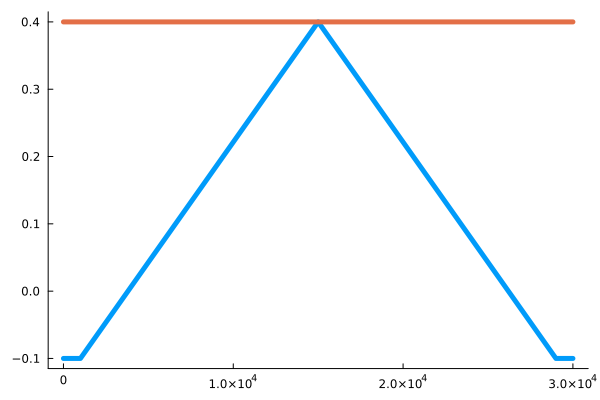

In [8]:
# #constant

inh_input=fill(1*amplitude, sim_length); #if we are using a constant inh

Plots.plot(commoninput,grid=false,legend=false, linewidth=5)
Plots.plot!(inh_input,grid=false,legend=false, linewidth=5)


In [85]:
full_input = zeros((nr_s, sim_length))
independantnoise = zeros((nr_s, sim_length))

factor= 0.1 #for creating the inhibitory signal
inh_input=fill(factor*amplitude, sim_length); #if we are using a constant inh

# tr=tr_new
# @time spike_array, vs_array    = run_sim();

@time spike_array, vs_array,pt_arr = run_sim_optim_constant_inh();


341.303352 seconds (15.94 G allocations: 265.527 GiB, 18.24% gc time, 0.06% compilation time)


In [162]:
# JLD2.@save "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/DR_87_TA_gamma0.7_VthCAoptim_29Jul.jld2" spike_array
JLD2.@save "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/DR_TA_0509.jld2" spike_array
# JLD2.@load "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/DR_89_VL_gamma0.7_VthCAoptim_28Jul.jld2" spike_array

In [7]:
# Plots.plot(vs_array[2,:]) #to plot the voltage as they do in old papers 
# Plots.plot(mt_arr[2,:]) #to plot the voltage as they do in old papers

In [280]:
# #PLOT THE STATE PARAMETERS
# fig = CairoMakie.Figure(resolution = (2000, 1000))

# rows = ceil(Int, sqrt(nr_s))
# cols = ceil(Int, nr_s / rows)

# for i in 1:nr_s
#     row = div(i - 1, cols) + 1
#     col = mod(i - 1, cols) + 1
    
#     ax = CairoMakie.Axis(fig[row, col])#) title = "Motoneuron $i", xlabel = "Time", ylabel = "Voltage")
    
#     CairoMakie.lines!(ax, vs_array[i, 1:600000], label = "Trace $i")
# end

# CairoMakie.display(fig)

# ##solve this basically there is a step every 500 points (0.05 ms)

##### Plotting with the excitatory input all together to compare

In [281]:
# amplitude=0.4;
# sim_length=560000 ;

# half_triang = div(sim_length, 2);  # Half the total length minus plateau length, rounding down if necessary
# flat_line = fill(-0.1, 20000);
# up = range(-0.1, amplitude, length = half_triang + 1)  ;
# down = range(amplitude, -0.1, length = sim_length - half_triang + 1);  
# tr = vcat(flat_line, up[2:end], down[2:end], flat_line);


# spike_times = []
# neuron_ids = []
# for i in 1:size(spike_array, 1)
#     spikes = findall(spike_array[i, :] .== 1) #when the MNs fires 
#     for t in spikes
#         push!(spike_times, [t, t])
#         push!(neuron_ids, [i - 0.4, i + 0.4])
#     end
# end

# Plots.plot(spike_times, neuron_ids, line=(1), legend=false, color =:gray,size=(800, 600),grid = false)
# Plots.plot!((tr/maximum(tr))*nr_s,line=(2), color =:red,grid = false)
# # xlabel!()
# # ylabel()


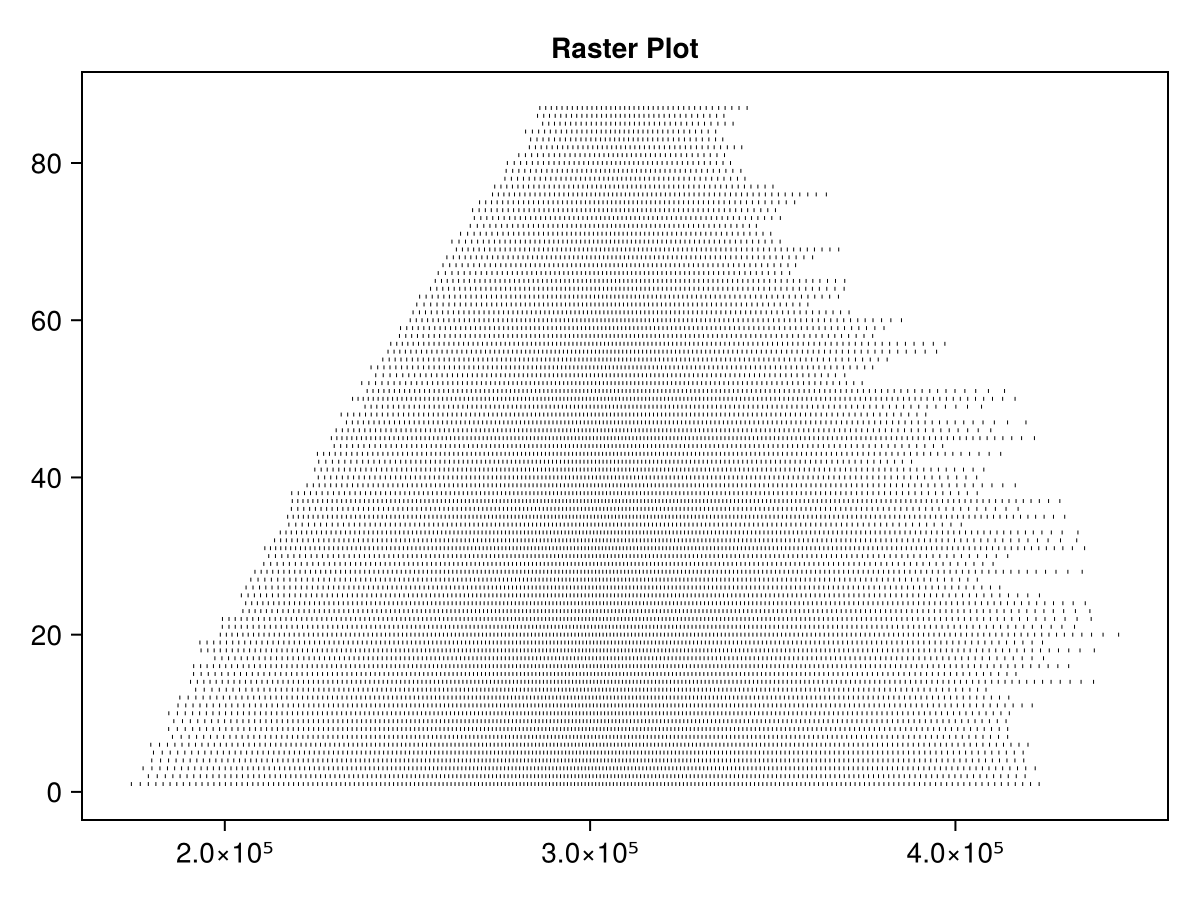

CairoMakie.Screen{IMAGE}


In [86]:
n_neurons, n_times = size(spike_array)
CairoMakie.activate!()

fig = CairoMakie.Figure()

ax = Axis(fig[1, 1], title="Raster Plot")
line_height = 0.5
line_thickness = 0.5

# Define a small horizontal offset between spikes
horizontal_offset = 100  # Adjust this value as needed to separate the spikes

for t in 1:n_times
    for neuron in 1:n_neurons
        if spike_array[neuron, t] == 1.0
            # Add a small horizontal offset to each spike for separation
            x_offset = horizontal_offset * (neuron - 1)  # Adjust the multiplier for spacing
            lines!(ax, [(t + x_offset, neuron - line_height / 2), (t + x_offset, neuron + line_height / 2)], color=:black, linewidth=line_thickness)
        end
    end
end
ax.xgridvisible = false
ax.ygridvisible = false
# xlabel!(ax, "Time")
# ylabel!(ax, "Neuron")a
display(fig)


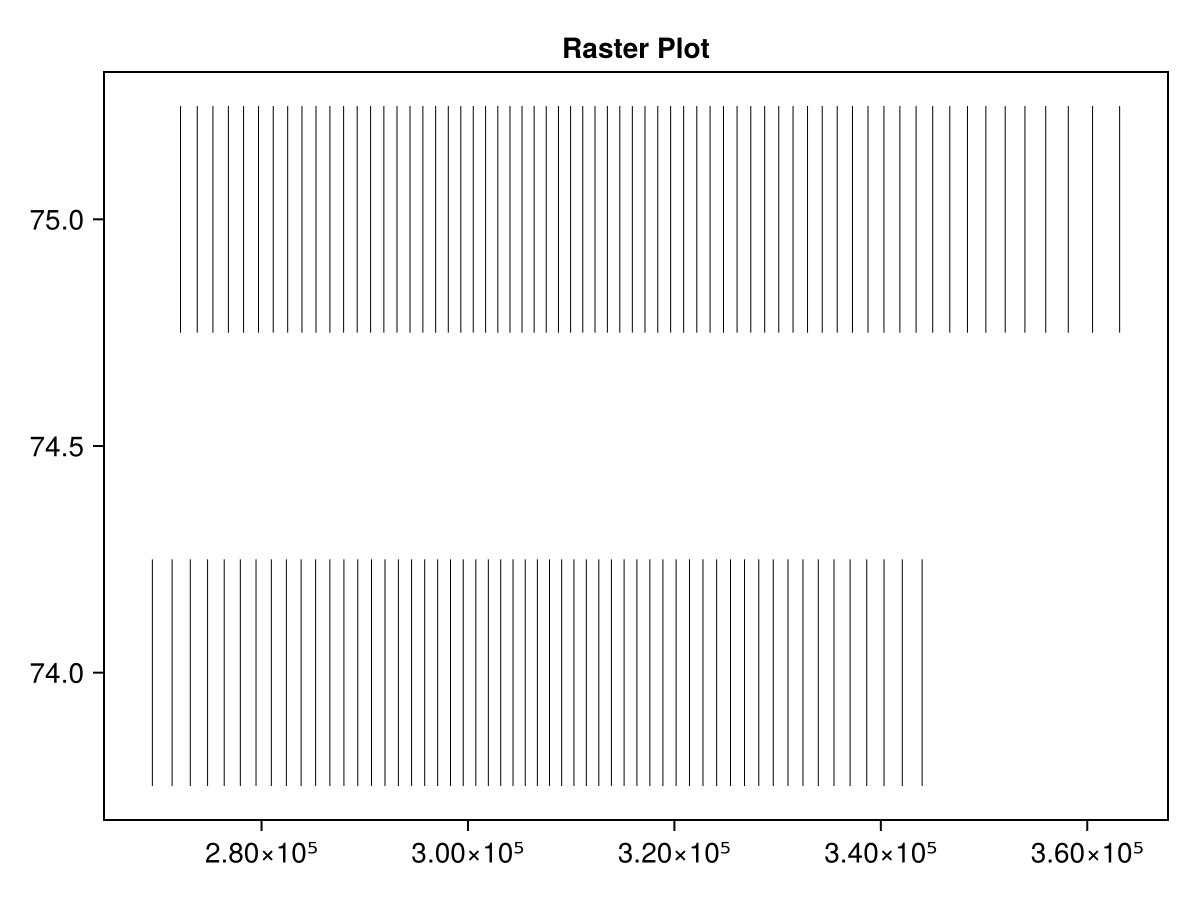

CairoMakie.Screen{IMAGE}


In [26]:
n_neurons, n_times = size(spike_array)
CairoMakie.activate!()

fig = CairoMakie.Figure()

ax = Axis(fig[1, 1], title="Raster Plot")
line_height = 0.5
line_thickness = 0.5

# Define a small horizontal offset between spikes
horizontal_offset = 100  # Adjust this value as needed to separate the spikes

for t in 1:n_times
    for neuron in [74,75]
        if spike_array[neuron, t] == 1.0
            # Add a small horizontal offset to each spike for separation
            x_offset = horizontal_offset * (neuron - 1)  # Adjust the multiplier for spacing
            lines!(ax, [(t + x_offset, neuron - line_height / 2), (t + x_offset, neuron + line_height / 2)], color=:black, linewidth=line_thickness)
        end
    end
end
ax.xgridvisible = false
ax.ygridvisible = false
# xlabel!(ax, "Time")
# ylabel!(ax, "Neuron")a
display(fig)


### Plot different state spaces

In [20]:

function conv_spikes_rates(array1,array2)
    window_samples = round(Int, 400 * 10^-3 * 20000) ; # 400 ms * 20 kHz  
    hanning_window = DSP.Windows.hanning(window_samples);
    hanning_window ./= sum(hanning_window);# Normalize the window so it sums to 1 (to maintain the same scale after convolution)

    smoothed_spike_array1 = conv(array1[1,:], hanning_window)/(1/20000)
    smoothed_spike_array2 = conv(array2[1,:], hanning_window)/(1/20000)

    # Because convolution extends the length of the array, let's truncate it to the original length
    len = size(array1,2);
    smoothed_spike_array1 = smoothed_spike_array1[1:len];
    smoothed_spike_array2 = smoothed_spike_array2[1:len];
    print("")

return smoothed_spike_array1, smoothed_spike_array2
end
   

conv_spikes_rates (generic function with 1 method)

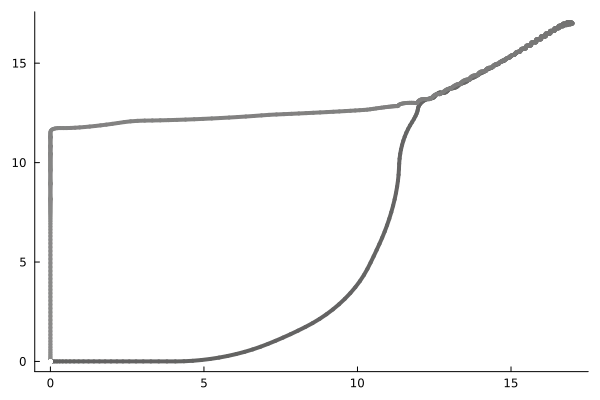

In [27]:
smoothed_spike_array1, smoothed_spike_array2 = conv_spikes_rates(reshape(spike_array[74,:],(1,length(spike_array[9,:]))), reshape(spike_array[75,:],(1,length(spike_array[12,:]))))
trajectory2_controlled = hcat(smoothed_spike_array1, smoothed_spike_array2)  

v = 100
n = div(size(trajectory2_controlled, 1), v)
new_avg = zeros(n, 2)
for i in 1:n
    start_idx = (i - 1) * v + 1
    end_idx = i * v
    new_avg[i, 1] = mean(trajectory2_controlled[start_idx:end_idx, 1])
    new_avg[i, 2] = mean(trajectory2_controlled[start_idx:end_idx, 2])
end

trajectory2_controlled = new_avg;


color_map = [get(ColorSchemes.grays, i) for i in LinRange(0, 1, size(trajectory2_controlled, 1))]

lines_x = []
lines_y = []
colors = []

for i in 1:(size(trajectory2_controlled, 1) - 1)
    push!(lines_x, [trajectory2_controlled[i, 1], trajectory2_controlled[i + 1, 1]])
    push!(lines_y, [trajectory2_controlled[i, 2], trajectory2_controlled[i + 1, 2]])
    push!(colors, color_map[i])
end

p = Plots.plot(legend=false, grid=false)
for i in 1:length(lines_x)
    Plots.plot!(p, lines_x[i], lines_y[i], color=colors[i], linewidth=4)
end

display(p)

##### Faster way to plot for a Raster Visualitation

# W&B - Hyperparameter sweep to explore the whole range of possible values

#### at some points add these functions outside here 

In [128]:
function simulate_hh_hysteresis_constant_inh(γh::Vector,i,MN_list)    
    MN_list[i][:γh] = γh[1]

    MNs= MN_list[i]

    spike_array, _ = run_sim_optim_constant_inh(i);

    amplitude=0.4;
    sim_length=560000 ;
    half_triang = div(sim_length, 2);  
    flat_line = fill(-0.1, 20000);
    up = range(-0.1, amplitude, length = half_triang + 1)  ;
    down = range(amplitude, -0.1, length = sim_length - half_triang + 1);  
    tr = vcat(flat_line, up[2:end], down[2:end], flat_line);
    equiv_force_profile= tr

    hysteresis= []

    if !isempty(spike_array) && any(spike_array[1, :] .== 1)
            
        value_1= equiv_force_profile[findfirst(==(1),spike_array[1,:]),:] #force at the recruitment threshold
        value_2=  equiv_force_profile[findlast(==(1),spike_array[1,:]),:] #force at the derecruitment threshold
        hysteresis= (value_2/value_1).-1

    else
        hysteresis=500 #random high value
    end

    max_firing_rates= [] #firing_rates_max(spike_array,i)
    
    return hysteresis, max_firing_rates
end


function run_sim_optim_constant_inh(i)

    full_input = commoninput 
    _, vs, _ = ode4(tspan, 0.,0., i, pool_state_params[i], full_input,inh_input, MNs)       
    # _, vs, _ = ode4(tspan, 0.,0., i, pool_state_params[i], full_input, full_input*factor, MNs)       
    spikes = spikes_from_aps(vs, i, MNs)       
    spike_arr = reshape(spikes, 1, length(spikes))
    vs_arr[i,:] = vs
    return spike_arr, vs_arr
end




function firing_rates_max(spike_array,i)

    max_rates_mns=[]
    for i in 1: size(spike_array)[1]
        spike_pos=[]
        for j in 1:size(spike_array)[2]
            if spike_array[i,j]==1.0
                push!(spike_pos,j)
            end
        end
        ISI= diff(spike_pos);
        rates= 1 ./(ISI/20000)
        max_rates= maximum(rates)
        max_rates_mns=max_rates
        
    end
    
    max_rate_mn= max_rates_mns;
    
    return max_rate_mn;
    
    end




firing_rates_max (generic function with 1 method)

In [15]:
i = 1

γh_range = LinRange(0., 1., 10)[1]
factor_range = LinRange(-1., 1., 10)

inh_input = []

for j in 1:length(γh_range)
    
    for k in 1:length(factor_range)

        run_name = "gamma_h_" * string(γh_range[j]) * "_inh_" * string(amplitude*factor_range[k])
        lg = WandbLogger(project="MN1", name=run_name, config=Dict("gamma_h" => γh_range[j], "inh" => factor_range[k]*amplitude))


        MN_list[i][:γh] = γh_range[j]


        inh_input = fill(factor_range[k] * amplitude, sim_length)

        hysteresis, _ = simulate_hh_hysteresis_constant_inh([γh_range[j]], i, MN_list)

        Wandb.log(lg, Dict("gamma_h" => γh_range[j], "inh" => inh_input[1], "hysteresis" => hysteresis))

        Wandb.close(lg)
    end
end



wandb: Currently logged in as: nmt121 (natmtc). Use `wandb login --relogin` to force relogin
wandb: wandb version 0.17.0 is available!  To upgrade, please run:
wandb:  $ pip install wandb --upgrade
wandb: Tracking run with wandb version 0.16.4
wandb: Run data is saved locally in /Users/nmt121/Desktop/Repositories/Motoneuron_Model/wandb/run-20240526_221316-q4w6rlcq
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run gamma_h_0.0_inh_-0.4
wandb:  View project at https://wandb.ai/natmtc/MN1
wandb:  View run at https://wandb.ai/natmtc/MN1/runs/q4w6rlcq


InterruptException: InterruptException:

In [138]:
i = 1

γh_range = LinRange(0., 1., 10)[10]
vtha_vals = LinRange(0., 5, 10)

inh_input = []

for j in 1:length(γh_range)
    
    for k in 1:length(vtha_vals)

        run_name = "gamma_h_" * string(γh_range[j]) * "vthca" * string(vtha_vals[k])

        lg = WandbLogger(project="trial1.1", name=run_name, config=Dict("gamma_h" => γh_range[j], "vthca" => vtha_vals))


        MN_list[i][:γh] = γh_range[j]
        MN_list[i][:VthCa] = vtha_vals[k]

        inh_input = fill(0.1* amplitude, sim_length)

        hysteresis, _ = simulate_hh_hysteresis_constant_inh([γh_range[j]], i, MN_list)

        Wandb.log(lg, Dict("gamma_h" => γh_range[j], "vthca" =>vtha_vals[k] , "hysteresis" => hysteresis))

        Wandb.close(lg)
    end
end



wandb: wandb version 0.17.0 is available!  To upgrade, please run:
wandb:  $ pip install wandb --upgrade
wandb: Tracking run with wandb version 0.16.4
wandb: Run data is saved locally in /Users/nmt121/Desktop/Repositories/Motoneuron_Model/wandb/run-20240528_221511-jeorwlui
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run gamma_h_1.0vthca5.0
wandb:  View project at https://wandb.ai/natmtc/trial1.1
wandb:  View run at https://wandb.ai/natmtc/trial1.1/runs/jeorwlui
wandb: WARNING No program path found, not creating job artifact. See https://docs.wandb.ai/guides/launch/create-job
wandb:                                                                                
wandb: 
wandb: Run summary:
wandb:    gamma_h 1.0
wandb: hysteresis -0.51056
wandb:      vthca 5.0
wandb: 
wandb:  View run gamma_h_1.0vthca5.0 at: https://wandb.ai/natmtc/trial1.1/runs/jeorwlui
wandb: Synced 4 W&B file(s), 0 media file(s), 0 artifact file(s) and 0 other file(s)
wandb: Find logs at: ./wandb/run

In [141]:
i = 1

γh_range = LinRange(0., 1., 5)
vtha_vals = LinRange(0., 5, 5)

inh_input = []

for j in 1:length(γh_range)
    
    for k in 1:length(vtha_vals)

        run_name = "gamma_h_" * string(γh_range[j]) * "vthca" * string(vtha_vals[k])

        lg = WandbLogger(project="trial1.3", name=run_name, config=Dict("gamma_h" => γh_range[j], "vthca" => vtha_vals))


        MN_list[i][:γh] = γh_range[j]
        MN_list[i][:VthCa] = vtha_vals[k]

        inh_input = fill(0.1* amplitude, sim_length)

        hysteresis, _ = simulate_hh_hysteresis_constant_inh([γh_range[j]], i, MN_list)

        Wandb.log(lg, Dict("gamma_h" => γh_range[j], "vthca" =>vtha_vals[k] , "hysteresis" => hysteresis))

        Wandb.close(lg)
    end
end



wandb: wandb version 0.17.0 is available!  To upgrade, please run:
wandb:  $ pip install wandb --upgrade
wandb: Tracking run with wandb version 0.16.4
wandb: Run data is saved locally in /Users/nmt121/Desktop/Repositories/Motoneuron_Model/wandb/run-20240528_222055-3ygb3k0u
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run gamma_h_0.0vthca0.0
wandb:  View project at https://wandb.ai/natmtc/trial1.3
wandb:  View run at https://wandb.ai/natmtc/trial1.3/runs/3ygb3k0u
wandb: WARNING No program path found, not creating job artifact. See https://docs.wandb.ai/guides/launch/create-job
wandb:                                                                                
wandb: 
wandb: Run summary:
wandb:    gamma_h 0.0
wandb: hysteresis 0.01562
wandb:      vthca 0.0
wandb: 
wandb:  View run gamma_h_0.0vthca0.0 at: https://wandb.ai/natmtc/trial1.3/runs/3ygb3k0u
wandb: Synced 4 W&B file(s), 0 media file(s), 0 artifact file(s) and 0 other file(s)
wandb: Find logs at: ./wandb/run-

In [35]:
Wandb.close(lg)

# Analysis of the distribution

### Computation of the hysteresis, recruitment and derecruitment threhsolds of the simulated MNs

In [87]:
amplitude=0.4;
sim_length=560000 ;
half_triang = div(sim_length, 2);  
flat_line = fill(-0.1, 20000);
up = range(-0.1, amplitude, length = half_triang + 1)  ;
down = range(amplitude, -0.1, length = sim_length - half_triang + 1);  
tr = vcat(flat_line, up[2:end], down[2:end], flat_line);

recr_inter_input= zeros(1,nr_s)
derecr_inter_input= zeros(1,nr_s)
hysteresis=zeros(1,nr_s)

for n in 1:nr_s
    if any(spike_array[n, :] .== 1)
        recr_inter_input[1,n]= tr[findfirst(==(1),spike_array[n,:]),:][1] #force at the recruitment threshold relative to the defined exc input
        derecr_inter_input[1,n]=  tr[findlast(==(1),spike_array[n,:]),:][1] #force at the derecruitment threshold
        hysteresis[1,n]= (derecr_inter_input[1,n]/recr_inter_input[1,n]).-1
    else #this is for the case in which for some reason there are no spikes for one of the neurons
        hysteresis[1,n]= -500
    end
end

In [8]:
JLD2.@save "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/relation_valueseta_recrthreshold/recr_VCa_9Jun.jld2" recr_inter_input
JLD2.@save "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/relation_valueseta_recrthreshold/decr_VCa_9Jun.jld2" derecr_inter_input
JLD2.@save "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/relation_valueseta_recrthreshold/hysteresis_9Jun.jld2" hysteresis

### Get the hysteresis, recruitment and derecruitment threhsolds of the experimental data

In [128]:
##ONLY RUN IF YOU ARE USING A SUBSAMPLE
data_exp = DataFrame(CSV.File("/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S5_short_hyst.csv"))
hysteresis_exp= (data_exp[:,2]./ data_exp[:,1]).-1; #(force(derecruitment)/force(recruitment))-1
recruitment_experimental_normal= data_exp[:,1];
derecruitment_experimental_normal= data_exp[:,2];

InterruptException: InterruptException:

In [26]:
# EXPERIMENTAL DATA , HYSTERESIS AND DECRECRUITMENT THRESHOLDS
df_hyst = CSV.read("/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/hysteresis.csv",DataFrame; header=false);
hysteresis_exp = df_hyst[:, 1];
df_recr = CSV.read("/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/recr_force.csv",DataFrame; header=false);
recruitment_experimental_normal = df_recr[:, 1];
df_derecr = CSV.read("/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/derecr_force.csv",DataFrame; header=false);
derecruitment_experimental_normal = df_derecr[:, 1];

In [17]:
# ## NORMALISE SIMULATED VALUES SO THEY ARE ALSO IN % OF MVC (KINDOF)
# function normalize_to_range(vector, new_min, new_max)
#     min_val = minimum(vector)
#     max_val = maximum(vector)
#     return ((vector .- min_val) / (max_val - min_val)) * (new_max - new_min) .+ new_min
# end

# #getting recruitment and derecruitment in terms of the %MVC
# simulated_values = vcat(recr_inter_input[1, :], derecr_inter_input[1, :])
# normalized_recr = normalize_to_range(simulated_values, 0, 100)
# recr_sim=  normalized_recr[1:nr_s]; derecr_sim=  normalized_recr[nr_s+1:(nr_s*2)];
# println("Normalized Recr: ", recr_sim)
# println("Normalized Derecr: ", derecr_sim)

### Plot of the recruitment thresholds VS the hysteresis (SIMULATED) 

In [92]:
df_h = CSV.read("/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/histogramTA_hysteresis.csv",DataFrame; header=false);
# hyst_exp = df_h[:, 1];

# df_h = CSV.read("/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/histogramVL_hysteresis.csv",DataFrame; header=false);
hyst_exp = df_h[:, 1];

In [106]:
JLD2.@load "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/accuracy_optim_TA_6sept.jld2" sorted_minimum_values
JLD2.@load "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/indices_optim_TA_6sept.jld2" sorted_neuron_indices

s1= sorted_minimum_values
s11=sorted_neuron_indices
JLD2.@load "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/accuracy_optim_VL_7sept.jld2" sorted_minimum_values
JLD2.@load "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/indices_optim_VL_7sept.jld2" sorted_neuron_indices

Plots.scatter(s11, s1, xlabel="MN", ylabel="Error", line=:solid,grid=false,label=false,ylim=(-0.1, 2),color=:green,alpha=0.5)
Plots.scatter!(sorted_neuron_indices, sorted_minimum_values, xlabel="MN", ylabel="Error", line=:solid,grid=false,label=false,ylim=(-0.1, 0.1),color=:red,alpha=0.5)

1-element Vector{Symbol}:
 :sorted_neuron_indices

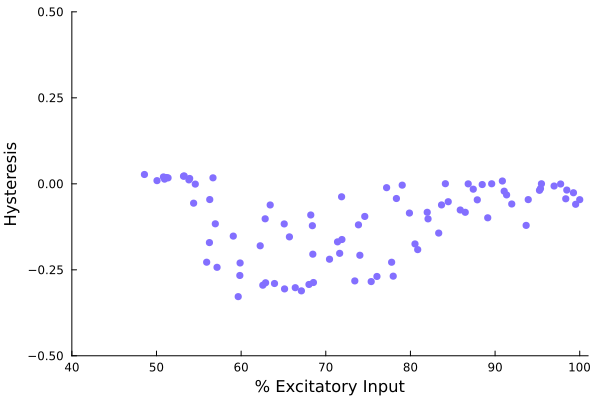

In [88]:
Plots.scatter(recr_inter_input/maximum(recr_inter_input)*100, hysteresis, grid=false,legend=false, xlabel="% Excitatory Input",ylabel="Hysteresis",xlim=(40,101),ylim=(-.5, .5), markercolor=:slateblue1, markerstrokecolor=:slateblue1)
# Plots.scatter!((recr_inter_input/maximum(recr_inter_input)*100)[1,:], hyst_exp, grid=false,legend=false, xlabel="% Excitatory Input",ylabel="Hysteresis",xlim=(40,101),ylim=(-.5, 0.1),color=:seagreen3,markercolor=:seagreen3,markerstrokewidth=0)

### Polynomial fittings

R^2 for Hysteresis: 0.5209517017942179


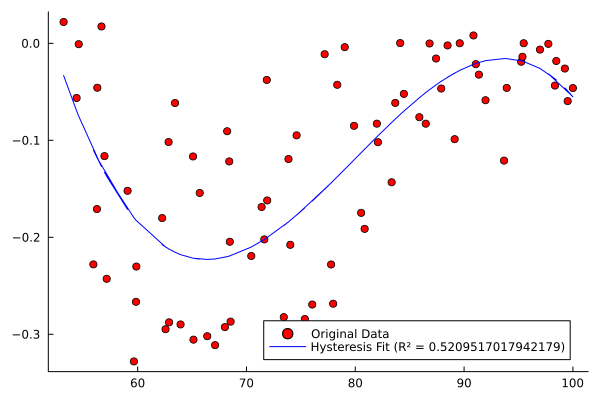

In [90]:
x = recr_inter_input / maximum(recr_inter_input) * 100
x_data = x[1,10:nr_s] 

hysteresis_s=hysteresis[1,10:nr_s]

poly_hysteresis_s = Polynomials.fit(x_data, hysteresis_s, 3)

# # Generate fitted values
y_fit_hysteresis = poly_hysteresis_s.(x_data)

ss_res_hysteresis = sum((hysteresis_s .- y_fit_hysteresis).^2)
ss_tot_hysteresis = sum((hysteresis_s .- mean(hysteresis)).^2)
r2_hysteresis = 1 - ss_res_hysteresis / ss_tot_hysteresis


# Print the R^2 values
println("R^2 for Hysteresis: ", r2_hysteresis)

# # Plot the original data and the polynomial fits
Plots.scatter(x_data, hysteresis_s, label="Original Data", color=:red,grid=false)
Plots.plot!(x_data, poly_hysteresis_s.(x_data), label="Hysteresis Fit (R² = $r2_hysteresis)", color=:blue)


R^2 for Hysteresis: 0.422060556329667


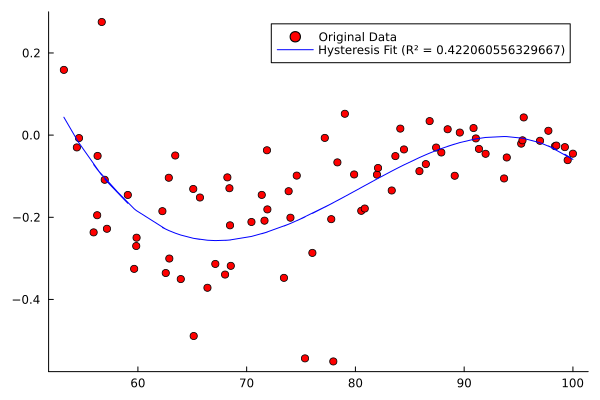

In [94]:
x = recr_inter_input / maximum(recr_inter_input) * 100
x_data = x[1,10:nr_s] 

hysteresis_e=hyst_exp[10:nr_s]

poly_hysteresis = Polynomials.fit(x_data, hysteresis_e, 3)

# # Generate fitted values
y_fit_hysteresis = poly_hysteresis.(x_data)

ss_res_hysteresis = sum((hysteresis_e .- y_fit_hysteresis).^2)
ss_tot_hysteresis = sum((hysteresis_e .- mean(hysteresis)).^2)
r2_hysteresis = 1 - ss_res_hysteresis / ss_tot_hysteresis


# Print the R^2 values
println("R^2 for Hysteresis: ", r2_hysteresis)

# # Plot the original data and the polynomial fits
Plots.scatter(x_data, hysteresis_e, label="Original Data", color=:red,grid=false)
Plots.plot!(x_data, poly_hysteresis.(x_data), label="Hysteresis Fit (R² = $r2_hysteresis)", color=:blue)


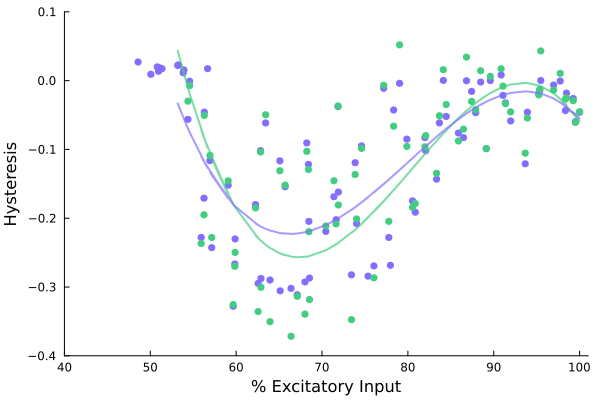

In [95]:
Plots.scatter(recr_inter_input/maximum(recr_inter_input)*100, hysteresis, grid=false,legend=false, xlabel="% Excitatory Input",ylabel="Hysteresis",xlim=(40,101),ylim=(-.4, .5), markercolor=:slateblue1, markerstrokecolor=:slateblue1)
Plots.scatter!((recr_inter_input/maximum(recr_inter_input)*100)[1,:], hyst_exp, grid=false,legend=false, xlabel="% Excitatory Input",ylabel="Hysteresis",xlim=(40,101),ylim=(-.4, 0.1),color=:seagreen3,markercolor=:seagreen3,markerstrokewidth=0)

Plots.plot!(x_data, poly_hysteresis.(x_data), label="Hysteresis Fit (R² = $r2_hysteresis)", color=:seagreen3,alpha=0.7,width=2)
Plots.plot!(x_data, poly_hysteresis_s.(x_data), label="Hysteresis Fit (R² = $r2_hysteresis)", color=:slateblue1,alpha=0.7,width=2)

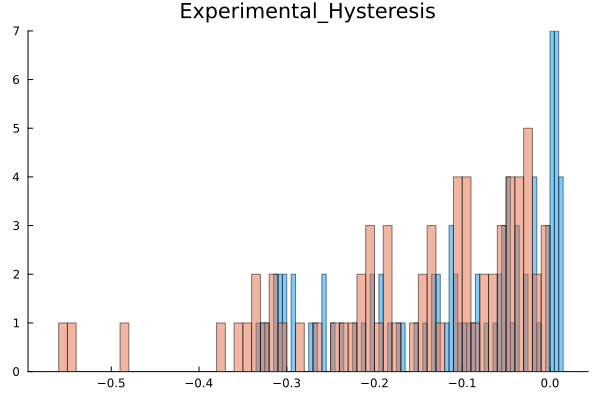

In [154]:
Plots.histogram( hysteresis[1,:],bins=100,grid=false,legend=false,title="Simulated Hysteresis",alpha=0.5)
Plots.histogram!( exp_h,bins=80,grid=false,legend=false,title="Experimental_Hysteresis",alpha=0.5)

### Interpolation of the values to obtain a "corrected" distribution

In [79]:
# ## RELATIONSHIP BETWEEN A SIZE PARAMETER AND THE RECRUITMENT THRESHOLD PLOT 

# p = Plots.plot(layout = (1, 1))
# Plots.plot!(p[1], rs_S, recr_sim, grid=false,legend=false, xlabel="Radius S",ylabel="Force at recruitment")
# # Plots.plot!(p[2], ls_S, recr_inter_input[1,:], grid=false,legend=false,xlabel="Length S",ylabel="Force at recruitment")
# # Plots.plot!(p[3], rd_S, recr_inter_input[1,:], grid=false,legend=false,xlabel="Radius D",ylabel="Force at recruitment")
# # Plots.plot!(p[4], ld_S, recr_inter_input[1,:], grid=false,legend=false,xlabel="Length D",ylabel="Force at recruitment")

# display(p)

In [28]:
regressed_parameter = zeros(11, nr_s)
vars= ["rs_S","ls_S","rms_S","rd_S","ld_S","rmd_S", "max_gks_S","max_gca_S","βp","Vthca_S","Apeak_S"]

for i in 1:11 #for each of the variables we are interested in
    for j in 1:nr_s
        var_interest= vars[i]
        var_interest= eval(Meta.parse(var_interest))
        X = hcat(ones(length(var_interest)), var_interest)
        model = lm(X, recr_inter_input[1,:]) 
        b = coef(model) 
        regressed_parameter[i,j] = (recruitment_experimental_normal[j]-b[1])/ b[2]
    end
end
regressed_parameter
JLD2.@save "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/regressed_parameter_87neurons_NOIF_NEW.jld2" regressed_parameter


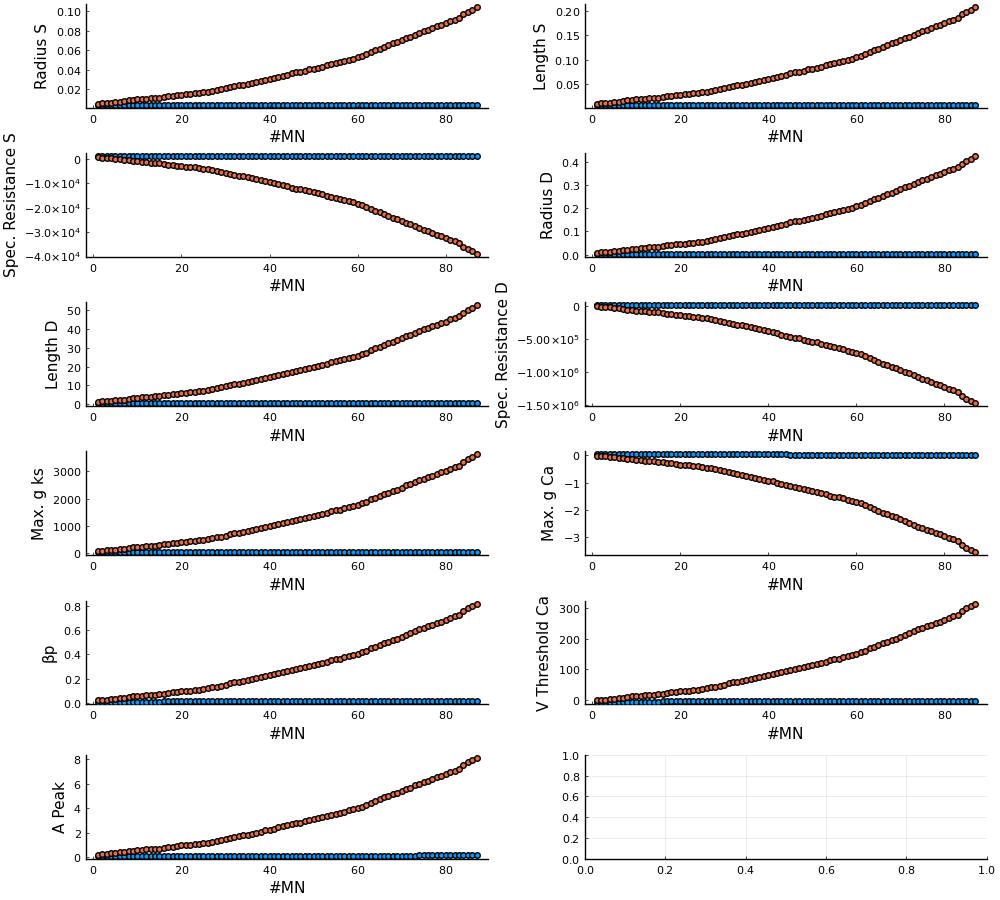

sys:1: UserWarning: No data for colormapping provided via 'c'. Parameters 'vmin', 'vmax' will be ignored
sys:1: UserWarning: No data for colormapping provided via 'c'. Parameters 'vmin', 'vmax' will be ignored
sys:1: UserWarning: No data for colormapping provided via 'c'. Parameters 'vmin', 'vmax' will be ignored
sys:1: UserWarning: No data for colormapping provided via 'c'. Parameters 'vmin', 'vmax' will be ignored


In [29]:
pyplot()  

default(size=(1000, 900))

p = Plots.plot(layout = (6, 2))

percent_changes = [(regressed_parameter[i, :] .- rs_S[i]) ./ rs_S[i] * 100 for i in 1:size(regressed_parameter, 1)]


r=1:87
Plots.scatter!(p[1,1], r, rs_S, grid=false, xlabel="#MN", ylabel="Radius S", legend=false)#label="Experimental Radius (Literature)")
Plots.scatter!(p[1,1], r, regressed_parameter[1,:], grid=false, legend=false)#label="Experimental Radius (Regressed from simulation)")

Plots.scatter!(p[1,2], r, ls_S, grid=false, xlabel="#MN", ylabel="Length S", legend=false)#label="Experimental Radius (Literature)")
Plots.scatter!(p[1,2], r, regressed_parameter[2,:], grid=false, legend=false)#label="Experimental Radius (Regressed from simulation)")

Plots.scatter!(p[2,1], r, rms_S, grid=false, xlabel="#MN", ylabel="Spec. Resistance S", legend=false)#label="Experimental Radius (Literature)")
Plots.scatter!(p[2,1],r, regressed_parameter[3,:], grid=false, legend=false)#label="Experimental Radius (Regressed from simulation)")

Plots.scatter!(p[2,2], r, rd_S, grid=false, xlabel="#MN", ylabel="Radius D",legend=false)#label="Experimental Radius (Literature)")
Plots.scatter!(p[2,2], r, regressed_parameter[4,:], grid=false, legend=false)#label="Experimental Radius (Regressed from simulation)")

Plots.scatter!(p[3,1], r, ld_S, grid=false, xlabel="#MN", ylabel="Length D", legend=false)#label="Experimental Radius (Literature)")
Plots.scatter!(p[3,1], r, regressed_parameter[5,:], grid=false, legend=false)#label="Experimental Radius (Regressed from simulation)")

Plots.scatter!(p[3,2], r, rmd_S, grid=false, xlabel="#MN", ylabel="Spec. Resistance D",  legend=false)#label="Experimental Radius (Literature)")
Plots.scatter!(p[3,2], r, regressed_parameter[6,:], grid=false, legend=false)#label="Experimental Radius (Regressed from simulation)")

Plots.scatter!(p[4,1], r, max_gks_S, grid=false, xlabel="#MN", ylabel="Max. g ks", legend=false)#label="Experimental Radius (Literature)")
Plots.scatter!(p[4,1], r, regressed_parameter[7,:], grid=false, legend=false)#label="Experimental Radius (Regressed from simulation)")

Plots.scatter!(p[4,2], r, max_gca_S, grid=false, xlabel="#MN", ylabel="Max. g Ca",  legend=false)#label="Experimental Radius (Literature)")
Plots.scatter!(p[4,2], r, regressed_parameter[8,:], grid=false, legend=false)#label="Experimental Radius (Regressed from simulation)")

Plots.scatter!(p[5,1],r, βp, grid=false, xlabel="#MN", ylabel="βp", legend=false)#label="Experimental Radius (Literature)")
Plots.scatter!(p[5,1], r, regressed_parameter[9,:], grid=false, legend=false)#label="Experimental Radius (Regressed from simulation)")

Plots.scatter!(p[5,2], r, Vthca_S, grid=false, xlabel="#MN", ylabel="V Threshold Ca",  legend=false)#label="Experimental Radius (Literature)")
Plots.scatter!(p[5,2], r, regressed_parameter[10,:], grid=false, legend=false)#label="Experimental Radius (Regressed from simulation)")

Plots.scatter!(p[6,1], r, Apeak_S, grid=false, xlabel="#MN", ylabel="A Peak", legend=false)#label="Experimental Radius (Literature)")
Plots.scatter!(p[6,1], r, regressed_parameter[11,:], grid=false, legend=false)#label="Experimental Radius (Regressed from simulation)")

# Finally, display the complete layout
display(p)


### Plot changed of the regressed parameters compared to the original parameters (that come from literature)

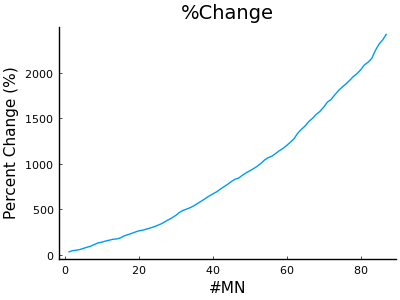

In [30]:
default(size=(400, 300))
Plots.plot(([(regressed_parameter[1, :] - rs_S) ./ rs_S * 100 for i in 1:12][1,:]), title="%Change", ylabel="Percent Change (%)", xlabel="#MN", legend=false, grid=false)  


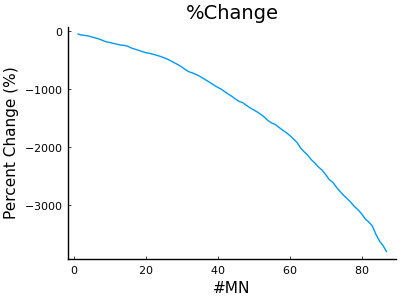

In [31]:
default(size=(400, 300))
Plots.plot(([(regressed_parameter[3, :] - rms_S) ./ rms_S * 100 for i in 1:12][1,:]), title="%Change", ylabel="Percent Change (%)", xlabel="#MN", legend=false, grid=false)  


# Computation of the rates 

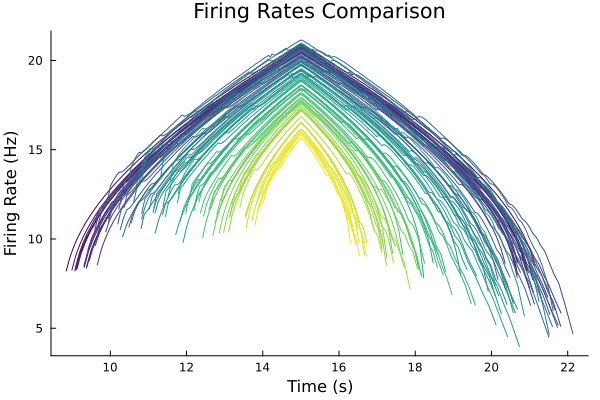

In [96]:
sampling_rate = 20000  # Hz

all_timebases = []
all_rates = []

for mn in 1:size(spike_array, 1)
    spike_pos = findall(x -> x == 1.0, spike_array[mn, :])
    timebase, rates = calculate_rates_with_timebase(spike_pos, sampling_rate)
    push!(all_timebases, timebase)
    push!(all_rates, rates)
end

color_map = get(ColorSchemes.viridis, LinRange(0, 1, size(spike_array, 1)))

p = Plots.plot(legend=false, grid=false, xlabel="Time (s)", ylabel="Firing Rate (Hz)", title="Firing Rates Comparison")
for i in 1:length(all_rates)
    if !isempty(all_rates[i])
        Plots.plot!(p, all_timebases[i], all_rates[i], color=color_map[i], legend=false, grid=false)
    end
end

display(p)


### Plot of recruitment threshold VS. max firing rates per motoneuron - they should follow a linear decrease

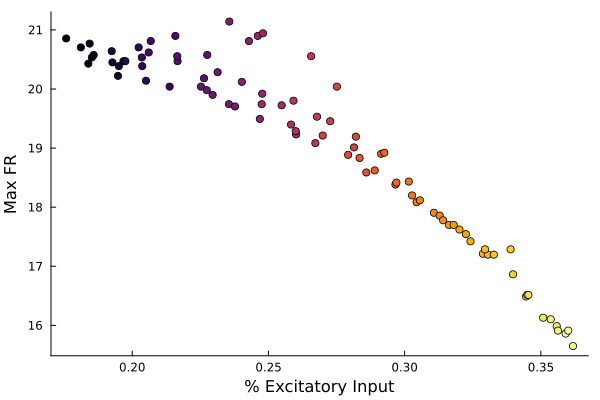

In [97]:
max_vals=zeros(1,nr_s)
color_map = get(ColorSchemes.inferno, LinRange(0, 1, size(spike_array, 1)))

p = Plots.plot(legend=false, grid=false)

for i in 1:nr_s
    if !isempty(all_rates[i])
        max_vals[1,i]=maximum(all_rates[i])
        Plots.scatter!([recr_inter_input[i]], [max_vals[1,i]],color=color_map[i], grid=false,legend=false, xlabel="% Excitatory Input",ylabel="Max FR")#,ylim=(-0.5, 0.5))
    end
end
# JLD2.@save "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/relation_valueseta_recrthreshold/max_fr_VCa_m3.jld2" max_vals
display(p)

In [22]:
max_vals[20:30]

11-element Vector{Float64}:
 21.762785636561482
 20.470829068577277
 20.2020202020202
 22.675736961451246
 20.449897750511248
 20.02002002002002
 20.0
 19.841269841269842
 22.753128555176335
 20.04008016032064
 19.704433497536943

In [30]:
MNs[23][:VthCa]

12.00262871728889

# Checking motoneuron similarity for the controller 

##### Find motoneurons that have the most similar recruitment thresholds

In [34]:
mn_that_is_similar = [Int[] for _ in 1:nr_s]

for i in 1:nr_s

    diff = zeros(Float64, nr_s)

    for j in 1:nr_s
        if i==j #do not compare the MN with itself
            diff[j] = NaN
        else
            diff[j] = abs(recr_inter_input[i] - recr_inter_input[j]) #compare recruitment threshold 
        end
    end

    min_diff = minimum(filter(!isnan, diff)) #find the minimum difference between recruitment thresholds of motoneurons 
    
    mn_that_is_similar[i] = findall(x -> x == min_diff, diff)   # find the most similar mn

end
mn_that_is_similar

87-element Vector{Vector{Int64}}:
 [2]
 [4]
 [5]
 [2]
 [7]
 [8]
 [5]
 [6]
 [12]
 [9]
 ⋮
 [83]
 [79]
 [80]
 [83]
 [82]
 [85]
 [84]
 [87]
 [86]

In [35]:
motoneuron = Int[]
recr_input = Float64[]
similar_motoneuron = Int[]
similar_recr_input = Float64[]
abs_diff = Float64[]

for i in 1:length(recr_inter_input)

    similar_idx = mn_that_is_similar[i][1]  
    diff_value = abs(Vthca_S[i] - Vthca_S[similar_idx])  #compute the diff of VthCa values
    
    push!(motoneuron, i)
    push!(recr_input, recr_inter_input[i])
    push!(similar_motoneuron, similar_idx)
    push!(similar_recr_input, recr_inter_input[similar_idx])
    push!(abs_diff, diff_value)
end

df = DataFrame(Motoneuron = motoneuron, Recr_Input = recr_input, Similar_Motoneuron = similar_motoneuron, Similar_Recr_Input = similar_recr_input, VthCa_Diff = abs_diff)
println(df)


87×5 DataFrame
 Row │ Motoneuron  Recr_Input  Similar_Motoneuron  Similar_Recr_Input  VthCa_Diff 
     │ Int64       Float64     Int64               Float64             Float64    
─────┼────────────────────────────────────────────────────────────────────────────
   1 │          1    0.178064                   2            0.181505   0.0
   2 │          2    0.181505                   4            0.181663   0.0
   3 │          3    0.186312                   5            0.190257   0.0
   4 │          4    0.181663                   2            0.181505   0.0
   5 │          5    0.190257                   7            0.190479   0.0
   6 │          6    0.19172                    8            0.1914     0.0
   7 │          7    0.190479                   5            0.190257   0.0
   8 │          8    0.1914                     6            0.19172    0.0
   9 │          9    0.197295                  12            0.198227   0.545305
  10 │         10    0.195475                  

In [30]:
findmax(df.VthCa_Diff)

(2.360427670561768, 47)

In [31]:
findmin(df.VthCa_Diff)

(0.0, 1)